In [1]:
import os
import random
import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import shutil

from ultralytics import YOLO
from sklearn.model_selection import train_test_split


In [2]:
SEED = 993

def seed_everything(seed=993):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

In [3]:
TRAIN_IMG = "2026-cv-competition/train/train/images"
TRAIN_LBL = "2026-cv-competition/train/train/labels"
TEST_IMG  = "2026-cv-competition/test/test/images"

In [4]:

images = os.listdir(TRAIN_IMG)
labels = os.listdir(TRAIN_LBL)

print("Images:", len(images))
print("Labels:", len(labels))

# Проверка соответствия
missing = 0
for img in images:
    lbl = img.replace(".jpg", ".txt").replace(".png", ".txt")
    if lbl not in labels:
        missing += 1

print("Images without labels:", missing)

Images: 1697
Labels: 1697
Images without labels: 0


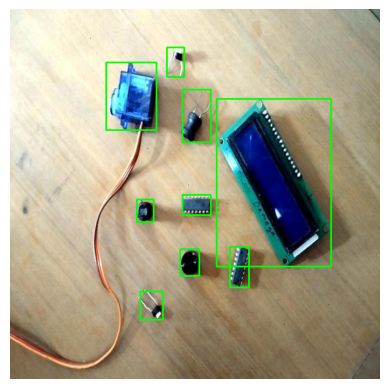

In [5]:
%matplotlib inline
def show_sample(idx=0):
    img_name = images[idx]
    img_path = os.path.join(TRAIN_IMG, img_name)
    lbl_path = os.path.join(TRAIN_LBL, img_name.replace(".jpg", ".txt").replace(".png", ".txt"))

    img = cv2.imread(img_path)
    h, w = img.shape[:2]

    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f.readlines():
                c, x, y, bw, bh = map(float, line.split())

                
                x1 = int((x - bw/2) * w)
                y1 = int((y - bh/2) * h)
                x2 = int((x + bw/2) * w)
                y2 = int((y + bh/2) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), (0,255,0), 2)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

show_sample(0)

In [6]:

BASE = "dataset"

for p in [
    f"{BASE}/images/train",
    f"{BASE}/images/val",
    f"{BASE}/labels/train",
    f"{BASE}/labels/val"
]:
    os.makedirs(p, exist_ok=True)

images = [f for f in os.listdir(TRAIN_IMG) if f.endswith((".jpg", ".png"))]
train_imgs, val_imgs = train_test_split(images, test_size=0.2, random_state=SEED)

def copy_split(img_list, split):
    for img in img_list:
        shutil.copy(f"{TRAIN_IMG}/{img}", f"{BASE}/images/{split}/{img}")

        lbl = img.replace(".jpg", ".txt").replace(".png", ".txt")
        src_lbl = f"{TRAIN_LBL}/{lbl}"

        if os.path.exists(src_lbl):
            shutil.copy(src_lbl, f"{BASE}/labels/{split}/{lbl}")

copy_split(train_imgs, "train")
copy_split(val_imgs, "val")

In [7]:
import glob, os

classes = set()
label_dir = "2026-cv-competition/train/train/labels"

for lbl_path in glob.glob(f"{label_dir}/*.txt"):
    with open(lbl_path) as f:
        for line in f:
            line = line.strip()
            if line:
                cls_id = int(line.split()[0])
                classes.add(cls_id)

num_classes = max(classes) + 1
print(f"Количество классов: {num_classes}")
print(f"ID классов: {sorted(classes)}")

Количество классов: 52
ID классов: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


In [8]:
NC = 52  

names_list = [f"class_{i}" for i in range(NC)]
names_str = "[" + ", ".join(f'"{n}"' for n in names_list) + "]"

data_yaml = f"""
path: {BASE}
train: images/train
val: images/val

nc: {NC}
names: {names_str}
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)



In [ ]:
import shutil, os

# Просто удаляем старую модель
if os.path.exists("runs/detect/train"):
    shutil.rmtree("runs/detect/train")
    

✅ Старая модель удалена


In [11]:
model = YOLO("yolov8s.pt") 

model.train(
    data="data.yaml",
    epochs=30,
    imgsz=320,
    batch=32,
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.15,
    degrees=10.0,
    patience=10,
)

New https://pypi.org/project/ultralytics/8.4.43 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.41 🚀 Python-3.13.2 torch-2.11.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.15, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=10.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x137877150>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033, 

In [12]:

model = YOLO("runs/detect/train/weights/best.pt")

results = model.predict(
    source=TEST_IMG, 
    conf=0.1, 
    iou=0.5, 
    imgsz=320, 
    augment=True
    )


image 1/424 /Users/sofkatulyakova/Documents/РАНХИГС /прогаа/ГО кагл дз2/2026-cv-competition/test/test/images/IMG20240228122809_jpg.rf.bb184f37aa98d96f1db1ac5492b4c81c.jpg: 320x320 1 class_0, 1 class_4, 2 class_10s, 1 class_12, 1 class_28, 1 class_30, 2 class_51s, 67.7ms
image 2/424 /Users/sofkatulyakova/Documents/РАНХИГС /прогаа/ГО кагл дз2/2026-cv-competition/test/test/images/IMG20240228122949_jpg.rf.f763b523e7bb4e72507961519cbbef88.jpg: 320x320 1 class_4, 1 class_6, 1 class_11, 2 class_26s, 1 class_28, 2 class_30s, 3 class_43s, 1 class_46, 4 class_51s, 49.3ms
image 3/424 /Users/sofkatulyakova/Documents/РАНХИГС /прогаа/ГО кагл дз2/2026-cv-competition/test/test/images/IMG20240228122955_jpg.rf.18d6c6ad9c8c69153da34c4074004853.jpg: 320x320 1 class_0, 1 class_2, 1 class_4, 1 class_11, 1 class_23, 1 class_26, 2 class_28s, 2 class_30s, 1 class_35, 3 class_43s, 1 class_44, 1 class_45, 2 class_46s, 1 class_50, 3 class_51s, 49.8ms
image 4/424 /Users/sofkatulyakova/Documents/РАНХИГС /прогаа/ГО

In [13]:
sample_df = pd.read_csv("2026-cv-competition/sample_submission.csv")

results_map = {}

for result in results:
    image_name = os.path.splitext(os.path.basename(result.path))[0]
    
    pred_parts = []
    
    if result.boxes is not None:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            conf = box.conf[0].item()
            cls = int(box.cls[0].item())
            
            pred_parts.extend([str(cls), f"{conf:.4f}", f"{x1:.2f}", f"{y1:.2f}", f"{x2:.2f}", f"{y2:.2f}"])
    
    results_map[image_name] = " ".join(pred_parts) if pred_parts else " "

final_submission = []

for row_id in sample_df["image_id"]:
    row_id_str = str(row_id).strip()
    
    found_pred = results_map.get(row_id_str, " ")  
    
    final_submission.append([row_id_str, found_pred])

df = pd.DataFrame(final_submission, columns=['image_id', 'PredictionString'])

df.to_csv('sample_submission.csv', index=False)

In [14]:

img = os.listdir("2026-cv-competition/train/train/images")[0]
lbl = img.replace(".jpg", ".txt").replace(".png", ".txt")

print(os.path.exists(f"2026-cv-competition/train/train/labels/{lbl}"))

True
